# Week 3 POC: PAN Card Field Extraction -- Local (Ollama + Qwen2.5-VL)

Applied POC per the Week 3 plan: use an existing pretrained VLM for real document-understanding, rather than training one from scratch (that was Week 2). Task: extract structured fields (name, father's name, DOB, PAN number) from scanned Indian PAN cards.

**Real data only.** `data/PAN_Kaggle/` (git-ignored) contains *real, unredacted* PAN cards scraped from the internet -- real names, real DOBs, real live PAN numbers belonging to real people. That's fine for a local-only robustness check (does the pipeline hold up against real scan noise, glare, skewed photos?), but real people's PAN numbers must never be sent to a cloud API, and must never be persisted as plaintext in a file that could get committed to git -- including this notebook's own saved cell outputs. So this notebook's main run (Section 4) **only ever computes and prints aggregate, PII-free statistics** (does the output look like a validly-shaped PAN number? is the name field non-empty? latency?) -- never the actual extracted values. A separate, clearly-marked "live spot check" cell exists for interactively eyeballing a single example, with an explicit warning not to save the notebook afterward if you use it.

A synthetic-data track was considered early on (to get exact, safe-to-persist ground truth) but was dropped per practice-head review: synthetic cards are too easy/gameable to be a meaningful signal, and this study works with real documents only. Real, quantitative accuracy numbers come from a manually-labeled subsample of real images instead -- see `poc/label_ground_truth.py` and `poc/model_comparison_report.ipynb` for that methodology, extended in Phase 2 to 5 models across PAN and Aadhaar.</cell id="cell-00">

## 1. Setup

In [ ]:
import json
import random
import re
import time
from pathlib import Path

import ollama
from PIL import Image

random.seed(42)

## 2. Configuration

`MODEL_NAME` must already be pulled locally (`ollama pull qwen2.5vl:7b`). The schema below is passed as Ollama's `format` parameter -- this constrains decoding to valid JSON matching this exact shape, so there's no fragile "hope the model outputs parseable JSON" prompt-engineering involved.

In [ ]:
MODEL_NAME = "qwen2.5vl:7b"

FIELD_SCHEMA = {
    "type": "object",
    "properties": {
        "name": {"type": "string", "description": "The PAN card holder's full name"},
        "father_name": {"type": "string", "description": "The holder's father's name"},
        "dob": {"type": "string", "description": "Date of birth as printed on the card"},
        "pan_number": {"type": "string", "description": "The 10-character PAN number"},
    },
    "required": ["name", "father_name", "dob", "pan_number"],
}

EXTRACTION_PROMPT = (
    "This is a scanned Indian PAN (Permanent Account Number) card. "
    "Extract the holder name, father name, date of birth, and PAN number exactly as printed. "
    "If a field is not legible, use an empty string for it."
)

REAL_PAN_DIR = Path("../data/PAN_Kaggle/train/images")
N_REAL_SAMPLES = 20

RESULTS_FILE = "local_results.json"

## 3. Extraction helper

Shared by both tracks. Returns the parsed fields dict (or `None` if the model's output somehow didn't parse, which the schema constraint should make rare) plus wall-clock latency.

In [8]:
def extract_pan_fields(image_path):
    t0 = time.time()
    response = ollama.chat(
        model=MODEL_NAME,
        messages=[{"role": "user", "content": EXTRACTION_PROMPT, "images": [str(image_path)]}],
        format=FIELD_SCHEMA,
    )
    latency = time.time() - t0
    try:
        fields = json.loads(response.message.content)
    except json.JSONDecodeError:
        fields = None
    tokens = {"prompt": response.prompt_eval_count, "output": response.eval_count}
    return fields, latency, tokens


## 4. Track A -- real PAN cards (local-only, PII-free aggregate stats)

Samples a fixed set of real images and validates the *shape* of each extracted field, not the actual value:

- `pan_number` matches the real PAN format (5 letters, 4 digits, 1 letter) -- `^[A-Z]{5}[0-9]{4}[A-Z]$`.
- `dob` matches a plausible `DD/MM/YYYY`-style date pattern.
- `name` / `father_name` are non-empty and look alphabetic (not garbage/empty).

None of the actual extracted names/DOBs/PAN numbers are ever stored in a variable that outlives this cell or printed anywhere -- only booleans and counts, which carry no PII and are safe to keep in this notebook's saved output.

In [9]:
PAN_FORMAT_RE = re.compile(r"^[A-Z]{5}[0-9]{4}[A-Z]$")
DATE_FORMAT_RE = re.compile(r"^\d{1,2}[/-]\d{1,2}[/-]\d{2,4}$")


def _looks_like_name(s):
    return bool(s) and bool(re.match(r"^[A-Za-z .]+$", s.strip()))


real_images = sorted(REAL_PAN_DIR.glob("*.jpg"))
print(f"Real PAN images available: {len(real_images)}")
sample = random.sample(real_images, min(N_REAL_SAMPLES, len(real_images)))

track_a_stats = {"n": 0, "json_parsed": 0, "pan_format_valid": 0, "dob_format_valid": 0,
                  "name_nonempty": 0, "father_name_nonempty": 0, "latencies": []}

for image_path in sample:
    fields, latency, _tokens = extract_pan_fields(image_path)
    track_a_stats["n"] += 1
    track_a_stats["latencies"].append(latency)
    if fields is None:
        continue
    track_a_stats["json_parsed"] += 1
    if PAN_FORMAT_RE.match(fields.get("pan_number", "").strip()):
        track_a_stats["pan_format_valid"] += 1
    if DATE_FORMAT_RE.match(fields.get("dob", "").strip()):
        track_a_stats["dob_format_valid"] += 1
    if _looks_like_name(fields.get("name", "")):
        track_a_stats["name_nonempty"] += 1
    if _looks_like_name(fields.get("father_name", "")):
        track_a_stats["father_name_nonempty"] += 1
    # Deliberately not printing or storing `fields` itself -- see Section 4's note.

n = track_a_stats["n"]
avg_latency = sum(track_a_stats["latencies"]) / n
print(f"\nTrack A -- real PAN cards, n={n} (aggregate stats only, no real values shown)")
print(f"  Valid JSON returned:        {track_a_stats['json_parsed']}/{n}")
print(f"  PAN number well-formatted:  {track_a_stats['pan_format_valid']}/{n}")
print(f"  DOB well-formatted:         {track_a_stats['dob_format_valid']}/{n}")
print(f"  Name field non-empty:       {track_a_stats['name_nonempty']}/{n}")
print(f"  Father name non-empty:      {track_a_stats['father_name_nonempty']}/{n}")
print(f"  Avg latency:                {avg_latency:.2f}s")


Real PAN images available: 1458

Track A -- real PAN cards, n=20 (aggregate stats only, no real values shown)
  Valid JSON returned:        20/20
  PAN number well-formatted:  19/20
  DOB well-formatted:         20/20
  Name field non-empty:       20/20
  Father name non-empty:      19/20
  Avg latency:                17.91s


### 4b. Optional live spot-check (do not save this notebook with this cell's output populated)

This is the only place real extracted values ever appear, and only in the live kernel -- not persisted by design. If you run this, either don't save the notebook afterward, or clear this cell's output before saving/committing.

In [10]:
def spot_check(index=0):
    """Prints one real card's extracted fields live, for manual eyeballing only.
    Do not save the notebook with this cell's output populated."""
    image_path = sample[index]
    fields, latency, _ = extract_pan_fields(image_path)
    print(f"[{image_path.name}]")
    print(fields)
    print(f"latency: {latency:.2f}s")


# Uncomment to run a live spot check -- remember the warning above.
# spot_check(0)


### 4c. Visual demo -- real PAN card + extracted fields (for internal review)

Shows the card image alongside its extracted fields, for a couple of real examples -- useful to show progress live (e.g. in a review), since Track A above deliberately only prints aggregate stats.

**This cell's output contains real PII** (a real person's name, DOB, PAN number, and photo) once run. That's fine for showing live on a screen, but:
- Do **not** commit this notebook with this cell's output populated.
- After your review, clear this cell's output (Edit -> Clear Outputs of Cell, or Kernel -> Restart & Clear Output) before saving, or just don't save the notebook at all.

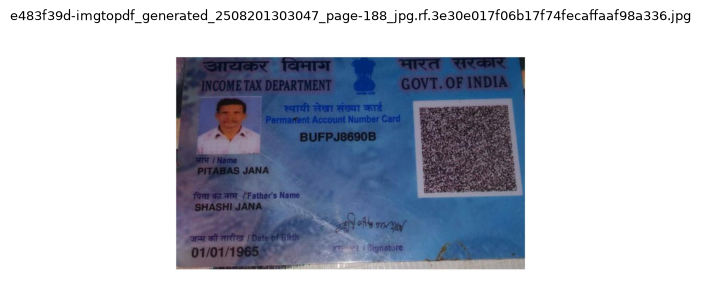

Extracted fields:
  name        : PITABAS JANA
  father_name : SHASHI JANA
  dob         : 01/01/1965
  pan_number  : BUFPJ8690B
  latency: 29.91s



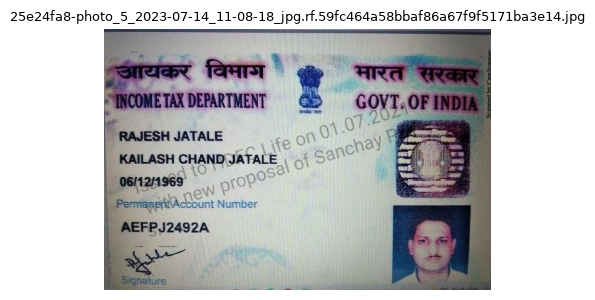

Extracted fields:
  name        : RAJESH JATALE
  father_name : KAILASH CHAND JATALE
  dob         : 06/12/1969
  pan_number  : AEFPJ2492A
  latency: 3.15s



In [11]:
import matplotlib.pyplot as plt


def show_extraction(image_path):
    fields, latency, _tokens = extract_pan_fields(image_path)
    img = Image.open(image_path)
    plt.figure(figsize=(5, 3.5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(image_path.name, fontsize=9)
    plt.show()
    print("Extracted fields:")
    for k, v in fields.items():
        print(f"  {k:<12}: {v}")
    print(f"  latency: {latency:.2f}s\n")


N_DEMO = 2
for demo_image_path in sample[:N_DEMO]:
    show_extraction(demo_image_path)

## 5. Save results

In [ ]:
local_results = {
    "model": MODEL_NAME,
    "track_a_real_data_aggregate_stats": track_a_stats,
}

with open(RESULTS_FILE, "w", encoding="utf-8") as f:
    json.dump(local_results, f, indent=2)

print(f"Saved local results to {RESULTS_FILE}")

## 6. Notes for the reading log / report

- **This notebook is a qualitative/robustness check, not a benchmark number** -- by design, Section 4 only ever looks at whether outputs are well-formed, never at whether they're *correct* (that would require persisting real people's data in this notebook's saved output, which we're deliberately not doing). The "well-formed" rate is still informative: it tells you whether the model is even attempting sensible answers on messy real scans, versus e.g. refusing or hallucinating garbage.
- **A synthetic-data track was tried and then dropped.** An earlier version of this notebook also ran a Track B against fully synthetic (Faker-generated) PAN cards, to get exact, safe-to-persist ground truth. Per practice-head review, synthetic cards were judged too easy/gameable to be meaningful signal, so that track -- and its generator script and generated images -- has been removed. This study now works with real documents only.
- **Real, quantitative accuracy** comes from a manually-labeled subsample of real images instead (`poc/label_ground_truth.py`), scored the same way in `poc/model_comparison_report.ipynb` -- extended in Phase 2 to 5 models across both PAN and Aadhaar.